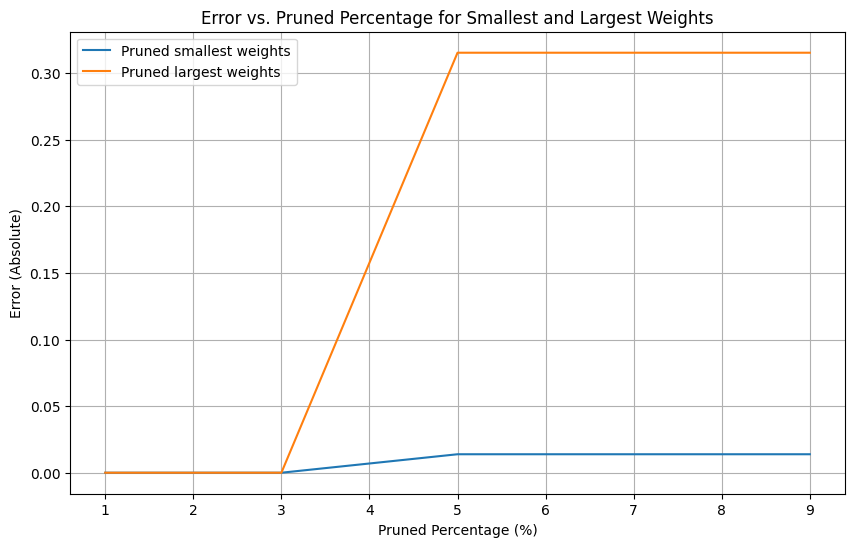

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid activation function
def logsig(x):
    return 1 / (1 + np.exp(-x))

def logsig_derivative(x):
    return logsig(x) * (1 - logsig(x))

# Linear activation function
def purelin(x):
    return x

def purelin_derivative(x):
    return 1

# Initialize parameters
p = 1
gt = 1 + np.sin((np.pi / 3) * p)  # Ground truth

# Hyperparameters
learning_rate = 0.05
iterations = 1000  # Training iterations

# Initialize weights and biases
np.random.seed(42)  # For reproducibility
W1 = np.random.uniform(-0.5, 0.5, (20, 1))
b1 = np.random.uniform(-0.5, 0.5, (20, 1))
W2 = np.random.uniform(-0.5, 0.5, (1, 20))
b2 = np.random.uniform(-0.5, 0.5, (1, 1))

# Training
errors = []
for _ in range(iterations):
    # Forward pass
    n1 = np.dot(W1, [[p]]) + b1
    a1 = logsig(n1)
    n2 = np.dot(W2, a1) + b2
    a2 = purelin(n2)

    # Compute error
    e = gt - a2
    errors.append(e[0][0])

    # Backpropagation
    s2 = -2 * purelin_derivative(n2) * e
    F1_prime = np.diagflat(logsig_derivative(n1))
    s1 = np.dot(F1_prime, np.dot(W2.T, s2))

    # Update weights and biases
    W2 -= learning_rate * np.dot(s2, a1.T)
    b2 -= learning_rate * s2
    W1 -= learning_rate * np.dot(s1, np.array([[p]]).T)
    b1 -= learning_rate * s1

# Save unpruned weights and biases
W1_unpruned, b1_unpruned, W2_unpruned, b2_unpruned = W1.copy(), b1.copy(), W2.copy(), b2.copy()

# Pruning Function
def prune_weights(W, percentage, prune_smallest=True):
    W_flat = W.flatten()
    num_to_prune = int(len(W_flat) * percentage / 100)
    if prune_smallest:
        indices = np.argsort(np.abs(W_flat))[:num_to_prune]
    else:
        indices = np.argsort(-np.abs(W_flat))[:num_to_prune]
    W_flat[indices] = 0  # Prune by setting weights to zero
    return W_flat.reshape(W.shape)

# Testing the pruned MLP
prune_percentages = list(range(1, 10, 2))  # 1% to 9% with step 2%
results = {"smallest": [], "largest": []}

for percentage in prune_percentages:
    # Prune smallest weights
    W1_pruned_small = prune_weights(W1_unpruned, percentage, prune_smallest=True)
    W2_pruned_small = prune_weights(W2_unpruned, percentage, prune_smallest=True)

    # Prune largest weights
    W1_pruned_large = prune_weights(W1_unpruned, percentage, prune_smallest=False)
    W2_pruned_large = prune_weights(W2_unpruned, percentage, prune_smallest=False)

    # Evaluate pruned networks
    for label, W1_pruned, W2_pruned in [("smallest", W1_pruned_small, W2_pruned_small),
                                        ("largest", W1_pruned_large, W2_pruned_large)]:
        # Forward pass with pruned weights
        n1_pruned = np.dot(W1_pruned, [[p]]) + b1_unpruned
        a1_pruned = logsig(n1_pruned)
        n2_pruned = np.dot(W2_pruned, a1_pruned) + b2_unpruned
        a2_pruned = purelin(n2_pruned)

        # Compute error
        pruned_error = np.abs(gt - a2_pruned[0][0])
        results[label].append((percentage, pruned_error))

# Plotting the results
plt.figure(figsize=(10, 6))
for label in results:
    percentages, errors = zip(*results[label])
    plt.plot(percentages, errors, label=f"Pruned {label} weights")

plt.xlabel("Pruned Percentage (%)")
plt.ylabel("Error (Absolute)")
plt.title("Error vs. Pruned Percentage for Smallest and Largest Weights")
plt.legend()
plt.grid()
plt.show()


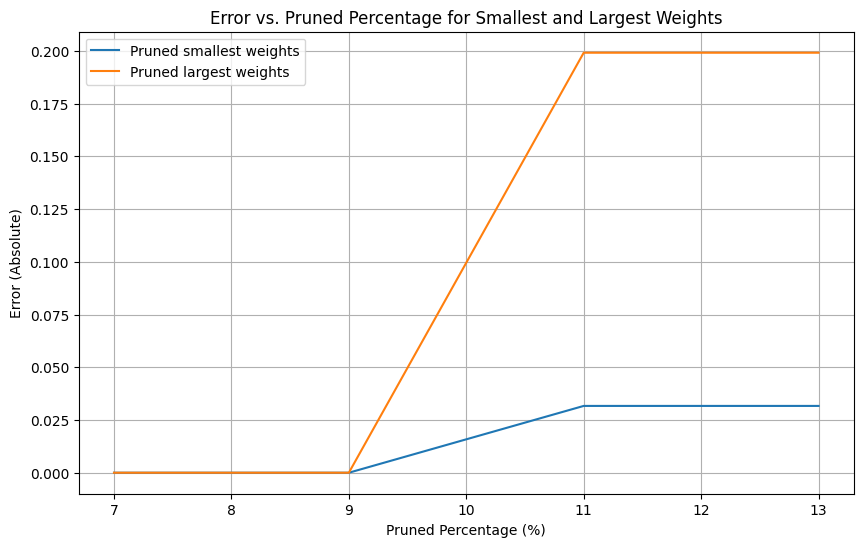

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Sigmoid activation function
def logsig(x):
    return 1 / (1 + np.exp(-x))

def logsig_derivative(x):
    return logsig(x) * (1 - logsig(x))

# Linear activation function
def purelin(x):
    return x

def purelin_derivative(x):
    return 1

# Initialize parameters
p = 1
gt = 1 + np.sin((np.pi / 3) * p)  # Ground truth

# Hyperparameters
learning_rate = 0.05
iterations = 1000  # Training iterations

# Initialize weights and biases
np.random.seed(42)  # For reproducibility
W1 = np.random.uniform(-0.5, 0.5, (10, 1))
b1 = np.random.uniform(-0.5, 0.5, (10, 1))
W2 = np.random.uniform(-0.5, 0.5, (1, 10))
b2 = np.random.uniform(-0.5, 0.5, (1, 1))

# Training
errors = []
for _ in range(iterations):
    # Forward pass
    n1 = np.dot(W1, [[p]]) + b1
    a1 = logsig(n1)
    n2 = np.dot(W2, a1) + b2
    a2 = purelin(n2)

    # Compute error
    e = gt - a2
    errors.append(e[0][0])

    # Backpropagation
    s2 = -2 * purelin_derivative(n2) * e
    F1_prime = np.diagflat(logsig_derivative(n1))
    s1 = np.dot(F1_prime, np.dot(W2.T, s2))

    # Update weights and biases
    W2 -= learning_rate * np.dot(s2, a1.T)
    b2 -= learning_rate * s2
    W1 -= learning_rate * np.dot(s1, np.array([[p]]).T)
    b1 -= learning_rate * s1

# Save unpruned weights and biases
W1_unpruned, b1_unpruned, W2_unpruned, b2_unpruned = W1.copy(), b1.copy(), W2.copy(), b2.copy()

# Pruning Function
def prune_weights(W, percentage, prune_smallest=True):
    W_flat = W.flatten()
    num_to_prune = int(len(W_flat) * percentage / 100)
    if prune_smallest:
        indices = np.argsort(np.abs(W_flat))[:num_to_prune]
    else:
        indices = np.argsort(-np.abs(W_flat))[:num_to_prune]
    W_flat[indices] = 0  # Prune by setting weights to zero
    return W_flat.reshape(W.shape)

# Testing the pruned MLP
prune_percentages = list(range(7, 15, 2))  # 1% to 9% with step 2%
results = {"smallest": [], "largest": []}

for percentage in prune_percentages:
    # Prune smallest weights
    W1_pruned_small = prune_weights(W1_unpruned, percentage, prune_smallest=True)
    W2_pruned_small = prune_weights(W2_unpruned, percentage, prune_smallest=True)

    # Prune largest weights
    W1_pruned_large = prune_weights(W1_unpruned, percentage, prune_smallest=False)
    W2_pruned_large = prune_weights(W2_unpruned, percentage, prune_smallest=False)

    # Evaluate pruned networks
    for label, W1_pruned, W2_pruned in [("smallest", W1_pruned_small, W2_pruned_small),
                                        ("largest", W1_pruned_large, W2_pruned_large)]:
        # Forward pass with pruned weights
        n1_pruned = np.dot(W1_pruned, [[p]]) + b1_unpruned
        a1_pruned = logsig(n1_pruned)
        n2_pruned = np.dot(W2_pruned, a1_pruned) + b2_unpruned
        a2_pruned = purelin(n2_pruned)

        # Compute error
        pruned_error = np.abs(gt - a2_pruned[0][0])
        results[label].append((percentage, pruned_error))

# Plotting the results
plt.figure(figsize=(10, 6))
for label in results:
    percentages, errors = zip(*results[label])
    plt.plot(percentages, errors, label=f"Pruned {label} weights")

plt.xlabel("Pruned Percentage (%)")
plt.ylabel("Error (Absolute)")
plt.title("Error vs. Pruned Percentage for Smallest and Largest Weights")
plt.legend()
plt.grid()
plt.show()
